# 02 — Supervised Learning, Dataset Construction and Naïve Forecasting

## 1. Research objective and forecasting problem

We investigate **NVIDIA's next-trading-session closing price**, expressed in Yahoo's retrospective **split-adjusted USD Close** convention. The forecast is issued after session $t$ closes, when $C_t$ and earlier observations are available. Its target is $C_{t+1}$, the Close of the next actual trading session—not necessarily the following calendar day.

The supervised dataset defines the information available to each prediction and the observation used to score it. Establishing this contract before comparing models prevents off-by-one errors, inconsistent evaluation dates and accidental access to future information. SPY and XLK are possible contextual inputs in the wider research; this notebook constructs the **one-feature NVIDIA representation** and its persistence benchmark.

**Scope.** We reconstruct development examples from the frozen snapshot, inspect their alignment and evaluate 2023–2024 forecasts. Training observations cover 2015–2022. **No reserved 2025 quote values or performance are loaded.** Dates in the partition diagram describe the research design only. Volume is excluded; Adjusted Close is not the target. No scaler, ARIMA model or neural network is fitted here.

Run all cells in order from the repository or `notebooks/` directory using the project environment. Reusable algorithms are imported from the actual Python modules. Tables, checks and figures remain in this notebook; execution does not write experiment artifacts.


In [1]:
from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import Markdown, display
from market_forecasting.data import load_yahoo_snapshot, snapshot_provenance
from market_forecasting.calendar import audit_sessions
from market_forecasting.dataset import (
    build_development_dataset, naive_predictions, error_metrics,
)

ROOT = Path.cwd() if (Path.cwd() / "configs/nvda.json").exists() else Path.cwd().parent
config_path = ROOT / "configs/nvda.json"
assert config_path.exists(), "Start from the repository or notebooks directory."
config = json.loads(config_path.read_text())
START = pd.Timestamp(config["start"])
TRAIN_END = pd.Timestamp(config["train_end"])
VALIDATION_END = pd.Timestamp(config["validation_end"])
TEST_END = pd.Timestamp(config["test_end"])
assert (START, TRAIN_END, VALIDATION_END, TEST_END) == tuple(pd.to_datetime(
    ["2015-01-01", "2022-12-31", "2024-12-31", "2025-12-31"]
)), "Review the temporal contract before changing this notebook's scope."
assert config["target_ticker"] == "NVDA"
assert config["price_convention"] == "split_adjusted_close"
assert config["forecast_horizon_trading_days"] == 1
assert config["initial_sequence_length"] == 30

get_ipython().run_line_magic("matplotlib", "inline")
pd.set_option("display.max_columns", 12)
plt.rcParams.update({"figure.dpi": 115, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .2})
BLUE, ORANGE, GREEN = "#2563eb", "#d97706", "#059669"


def dated_axis(ax):
    """Keep date labels readable at different time scales."""
    locator = mdates.AutoDateLocator(minticks=4, maxticks=8)
    ax.xaxis.set_major_locator(locator)
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))


def show_figure(fig):
    """Display inline without saving a separate figure file."""
    plt.show()
    plt.close(fig)

print(f"Permitted quote values: {START.date()}–{VALIDATION_END.date()}")


Permitted quote values: 2015-01-01–2024-12-31


## 2. From time-series data to supervised learning

A supervised example pairs information available at prediction time, $X_i$, with an outcome, $y_i$, that becomes available later. For a one-step price forecast:

| Term | Meaning in this study |
|---|---|
| Input features $X_i$ | A sequence of observed NVIDIA closes |
| Lookback $L$ | Number of trading sessions in that sequence |
| Forecast origin $t$ | Final observed session; the prediction is issued after its close |
| Target date $t+1$ | Next trading session |
| Target value $y_i$ | Actual Close on that next session |
| Forecast $\hat y_i$ | Prediction produced using information through the origin |

**Small example.** With a three-session lookback, `[100, 102, 101] → 104` means that the three prices form the input and the fourth is the label. The label can be stored beside the input for later evaluation; it must not be supplied to the prediction function. The next example shifts forward by one session: `[102, 101, 104] → 103`.

The following example calls the production builder with a clearly synthetic series. Its shorter lookback illustrates indexing; it does not change the NVIDIA configuration.


In [2]:
toy_dates = pd.to_datetime([
    "2020-01-02", "2020-01-03", "2020-01-06", "2020-01-07",
    "2020-01-08", "2020-01-09", "2020-01-10",
])
toy_close = pd.Series([100., 102., 101., 104., 103., 105., 106.], index=toy_dates)
toy_config = dict(config, start="2020-01-02", train_end="2020-01-08",
                  validation_end="2020-01-10", test_end="2020-01-31",
                  initial_sequence_length=3)
toy = build_development_dataset(toy_close, toy_config)
toy_table = toy.metadata.copy()
toy_table["input_prices_usd"] = [window[:, 0].tolist() for window in toy.X]
toy_table["target_close_usd"] = toy.y
display(toy_table)
np.testing.assert_array_equal(toy.X[0, :, 0], [100., 102., 101.])
assert toy.y[0] == 104.


,window_start,origin_date,target_date,split,input_prices_usd,target_close_usd
0,2020-01-02,2020-01-06,2020-01-07,train,"[100.0, 102.0, 101.0]",104.0
1,2020-01-03,2020-01-07,2020-01-08,train,"[102.0, 101.0, 104.0]",103.0
2,2020-01-06,2020-01-08,2020-01-09,validation,"[101.0, 104.0, 103.0]",105.0
3,2020-01-07,2020-01-09,2020-01-10,validation,"[104.0, 103.0, 105.0]",106.0


The table makes the separation visible: the origin is the last date represented in $X$, while the target date and $y$ are one observed session later. The first two examples belong to training by their **target** dates; the remaining examples belong to validation.

### Actual NVIDIA input: provenance and bounded loading

The acquisition checksum identifies the frozen snapshot without interpreting its full price history. `load_yahoo_snapshot()` selects the requested timestamp positions **before decoding quote values**, retains exchange-local session dates, and applies the project's financial-data validation. We explicitly stop at the validation boundary. Only `close` becomes a forecasting feature; the other validated fields are not model inputs.

The independent NASDAQ audit is essential: an ordered list can still omit a real trading session. Without this check, “next observed row” could incorrectly be treated as “next trading session.” Weekends, market holidays and half-days follow the exchange calendar; no rows are filled, sorted or silently discarded. A calendar-library comparison cannot independently certify the vendor's prices.


In [3]:
raw_path = ROOT / "data/raw" / f"{config['target_ticker']}_yahoo_snapshot.json"
provenance = snapshot_provenance(raw_path, ROOT / "docs/data_verification.json", "NVDA")
prices = load_yahoo_snapshot(raw_path, start=config["start"], end=config["validation_end"])
close = prices["close"]
calendar_audit = audit_sessions(close.index, config["start"], config["validation_end"], "NASDAQ")
assert not calendar_audit["missing"] and not calendar_audit["unexpected"]
assert calendar_audit["duplicate_dates"] == 0 and calendar_audit["ordered"]
assert START <= close.index.min() <= close.index.max() <= VALIDATION_END

source_summary = {
    "snapshot": provenance["snapshot"], "retrieved_utc": provenance["retrieved_utc"],
    "checksum_matches": provenance["checksum_matches"],
    "first_session": close.index.min().date(), "last_session": close.index.max().date(),
    "observed_sessions": len(close), "expected_sessions": calendar_audit["expected_sessions"],
    "missing_sessions": len(calendar_audit["missing"]),
    "unexpected_sessions": len(calendar_audit["unexpected"]),
    "duplicate_dates": calendar_audit["duplicate_dates"], "ordered": calendar_audit["ordered"],
}
display(pd.Series(source_summary, name="Bounded development input").to_frame())
display(pd.concat([close.head(3), close.tail(3)]).rename("close_usd").to_frame())


,Bounded development input
snapshot,NVDA_yahoo_snapshot.json
retrieved_utc,2026-10-11T09:07:25.380128+00:00
checksum_matches,True
first_session,2015-01-02
last_session,2024-12-31
observed_sessions,2516
expected_sessions,2516
missing_sessions,0
unexpected_sessions,0
duplicate_dates,0


,close_usd
date,
2015-01-02,0.503250
2015-01-05,0.494750
2015-01-06,0.479750
2024-12-27,137.009995
2024-12-30,137.490005
2024-12-31,134.289993


In [4]:
display(Markdown(
    f"**Evidence.** The permitted input contains **{len(close):,} observations**, "
    f"from **{close.index.min().date()}** to **{close.index.max().date()}**, "
    "with matching snapshot identity and no missing, unexpected or duplicated NASDAQ sessions. "
    "This establishes the session sequence used below; it does not prove that future prices are predictable."
))


**Evidence.** The permitted input contains **2,516 observations**, from **2015-01-02** to **2024-12-31**, with matching snapshot identity and no missing, unexpected or duplicated NASDAQ sessions. This establishes the session sequence used below; it does not prove that future prices are predictable.

## 3. Sliding-window construction

For a lookback of $L=30$ observed trading sessions, each example is

\[
X_i = [C_{t-L+1},\ldots,C_t]^\mathsf{T},\qquad y_i=C_{t+1}.
\]

The slice stops **before** the target. Adjacent windows overlap in $L-1=29$ observations: the oldest price leaves, the previous target becomes an observed input, and a new target follows. This overlap is normal sequential context, but the resulting examples are not independent observations.

Thirty **sessions** is longer than thirty calendar days when weekends and holidays intervene. It is a fixed representation for controlled comparison, not evidence that thirty is an optimal memory length. The first thirty records supply context for the first target; they are not erroneous or discarded observations.

`build_development_dataset()` owns window construction. The notebook only inspects its arrays and metadata.


In [5]:
dataset = build_development_dataset(close, config)
metadata = dataset.metadata
lookback = config["initial_sequence_length"]
window_examples = metadata.head(3).copy()
window_examples["first_three_closes_usd"] = [w[:3, 0].round(6).tolist() for w in dataset.X[:3]]
window_examples["last_three_closes_usd"] = [w[-3:, 0].round(6).tolist() for w in dataset.X[:3]]
window_examples["target_close_usd"] = dataset.y[:3]
display(window_examples)

# Consecutive examples must retain the same 29 overlapping observations.
np.testing.assert_array_equal(dataset.X[0, 1:, :], dataset.X[1, :-1, :])
np.testing.assert_array_equal(dataset.X[1, 1:, :], dataset.X[2, :-1, :])
assert dataset.X[1, -1, 0] == dataset.y[0]
first_span = (metadata.origin_date.iloc[0] - metadata.window_start.iloc[0]).days + 1
print(f"The first {lookback}-session input spans {first_span} calendar days (inclusive).")
print(f"First target: {metadata.target_date.iloc[0].date()}; overlap: {lookback - 1} observations.")


,window_start,origin_date,target_date,split,first_three_closes_usd,last_three_closes_usd,target_close_usd
0,2015-01-02,2015-02-13,2015-02-17,train,"[0.50325, 0.49475, 0.47975]","[0.52025, 0.5575, 0.55775]",0.5595
1,2015-01-05,2015-02-17,2015-02-18,train,"[0.49475, 0.47975, 0.4785]","[0.5575, 0.55775, 0.5595]",0.5530
2,2015-01-06,2015-02-18,2015-02-19,train,"[0.47975, 0.4785, 0.4965]","[0.55775, 0.5595, 0.553]",0.5545


The first 30-session input spans 43 calendar days (inclusive).
First target: 2015-02-17; overlap: 29 observations.


The origin-to-target interval can cross a weekend or holiday while remaining a **one-session** horizon. The displayed adjacent examples and equality checks confirm the shift directly. The first target occurs only once thirty historical observations are available.

## 4. Understanding dataset dimensions

Recurrent models receive a three-dimensional input tensor:

\[
X\in\mathbb{R}^{N\times L\times F}
= (\text{samples},\text{timesteps},\text{features}).
\]

- **Samples:** separate forecast opportunities, each with its own target date.
- **Timesteps:** the thirty ordered historical sessions within one sample.
- **Features:** one observed value per session here, NVIDIA Close.

`X[i, :, 0]` selects the complete Close sequence for sample `i`; `X[i, -1, 0]` selects its latest known price. `y[i]` is a scalar next-session target. The singleton feature axis is intentional: `(N, 30)` would omit the explicit feature dimension expected by an LSTM.

Additional indicators or market-context variables increase $F$, with each feature aligned to the same session and available by the origin. Warm-up requirements can also change $N$; additional features do not automatically preserve the set of eligible training examples.


In [6]:
shape_table = pd.DataFrame({
    "array": ["X", "y", "one sample X[0]", "one Close sequence X[0, :, 0]"],
    "actual_shape": [dataset.X.shape, dataset.y.shape, dataset.X[0].shape, dataset.X[0, :, 0].shape],
    "meaning": ["samples × sessions × features", "one scalar target per sample",
                "sessions × features", "ordered Close values"],
})
display(shape_table)
assert dataset.X.shape == (len(close) - lookback, lookback, 1)
assert dataset.y.shape == (dataset.X.shape[0],)
assert len(metadata) == len(dataset.y)
display(Markdown(
    f"**Calculated dimensions:** $X=({dataset.X.shape[0]}, {lookback}, 1)$ and "
    f"$y=({len(dataset.y)},)$. There are {len(close):,} observations minus "
    f"{lookback} initial context rows, giving **{len(dataset.y):,} development examples**."
))


,array,actual_shape,meaning
0,X,"(2486, 30, 1)",samples × sessions × features
1,y,"(2486,)",one scalar target per sample
2,one sample X[0],"(30, 1)",sessions × features
3,"one Close sequence X[0, :, 0]","(30,)",ordered Close values


**Calculated dimensions:** $X=(2486, 30, 1)$ and $y=(2486,)$. There are 2,516 observations minus 30 initial context rows, giving **2,486 development examples**.

## 5. Chronological dataset partitioning

Training data provide the observations permitted for fitting model parameters and transformations. Validation data assess development choices and compare models; repeated choices based on validation can still overfit that period. The final test interval remains reserved until a methodology is frozen.

The approved boundaries are **2015–2022 training**, **2023–2024 validation**, and **2025 final testing**. Partition membership is determined by the **target date**, not the start of its input window. Training examples consequently begin after the thirty-session context requirement has been met.

Randomly distributing overlapping windows would interleave future and earlier targets across partitions and share near-identical sequences. That would not measure the intended task of forecasting forward into a later period. Chronological partitions preserve this ordering; they do not make neighbouring errors statistically independent.


,examples,first_target,last_target,first_origin
split,,,,
train,1984,2015-02-17,2022-12-30,2015-02-13
validation,502,2023-01-03,2024-12-31,2022-12-30


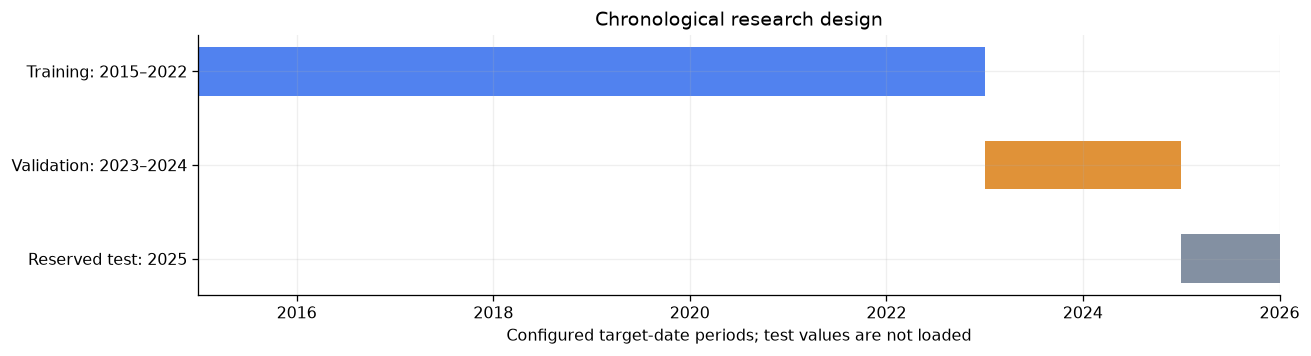

In [7]:
train_mask = metadata["split"].eq("train").to_numpy()
validation_mask = metadata["split"].eq("validation").to_numpy()
partition_table = metadata.groupby("split", sort=False).agg(
    examples=("target_date", "size"), first_target=("target_date", "min"),
    last_target=("target_date", "max"), first_origin=("origin_date", "min"),
)
display(partition_table)
assert train_mask.sum() == int((close.index <= TRAIN_END).sum()) - lookback
assert validation_mask.sum() == int((close.index > TRAIN_END).sum())
assert metadata.loc[train_mask, "target_date"].max() <= TRAIN_END
assert metadata.loc[validation_mask, "target_date"].min() > TRAIN_END
assert metadata.target_date.max() <= VALIDATION_END

# The reserved interval is drawn from configuration dates, with no test observations.
fig, ax = plt.subplots(figsize=(11.5, 3.2))
periods = [(START, TRAIN_END, "Training: 2015–2022", BLUE),
           (TRAIN_END + pd.Timedelta(days=1), VALIDATION_END, "Validation: 2023–2024", ORANGE),
           (VALIDATION_END + pd.Timedelta(days=1), TEST_END, "Reserved test: 2025", "#64748b")]
for y, (left, right, label, color) in enumerate(periods):
    x0 = mdates.date2num(left)
    width = mdates.date2num(right + pd.Timedelta(days=1)) - x0
    ax.barh(y, width, left=x0, color=color, height=.52, alpha=.8)
ax.set_yticks(range(3), [p[2] for p in periods])
ax.invert_yaxis()
ax.xaxis.set_major_locator(mdates.YearLocator(2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.set_xlim(START, TEST_END + pd.Timedelta(days=1))
ax.set_xlabel("Configured target-date periods; test values are not loaded")
ax.set_title("Chronological research design")
fig.tight_layout()
show_figure(fig)


In [8]:
display(Markdown(
    f"**Observed partition sizes:** {train_mask.sum():,} training targets and "
    f"{validation_mask.sum():,} validation targets. Training ends at "
    f"{metadata.loc[train_mask, 'target_date'].max().date()}; validation targets run from "
    f"{metadata.loc[validation_mask, 'target_date'].min().date()} to "
    f"{metadata.loc[validation_mask, 'target_date'].max().date()}. "
    "Weekend and holiday boundaries need not themselves be observed sessions."
))


**Observed partition sizes:** 1,984 training targets and 502 validation targets. Training ends at 2022-12-30; validation targets run from 2023-01-03 to 2024-12-31. Weekend and holiday boundaries need not themselves be observed sessions.

## 6. Temporal leakage prevention

Leakage occurs when a forecast or a fitted transformation uses information unavailable at its stated forecast origin. For a valid one-step prediction, every input session must be at or before the origin, and the target must be the **next audited session**.

A validation input may include training observations because they are already historical. After the first validation target closes, its actual price can enter the next forecast's context. This is **rolling one-step evaluation**, not a forecast of the entire validation period issued at the end of training. It also differs from refitting model parameters on validation targets.

The following boundary examples show what is known at each origin. Keeping `X` and `y` together in an evaluation object is convenient, but the baseline's production prediction function reads only `X[:, -1, 0]`.


In [9]:
first_validation_i = int(np.flatnonzero(validation_mask)[0])
boundary = metadata.loc[first_validation_i:first_validation_i + 2].copy()
boundary["latest_available_close_usd"] = dataset.X[first_validation_i:first_validation_i + 3, -1, 0]
boundary["later_target_close_usd"] = dataset.y[first_validation_i:first_validation_i + 3]
display(boundary)
assert metadata.loc[first_validation_i, "origin_date"] == pd.Timestamp("2022-12-30")
assert metadata.loc[first_validation_i, "target_date"] == pd.Timestamp("2023-01-03")
assert (metadata.origin_date < metadata.target_date).all()


,window_start,origin_date,target_date,split,latest_available_close_usd,later_target_close_usd
1984,2022-11-17,2022-12-30,2023-01-03,validation,14.614,14.315
1985,2022-11-18,2023-01-03,2023-01-04,validation,14.315,14.749
1986,2022-11-21,2023-01-04,2023-01-05,validation,14.749,14.265


### A valid prediction and an invalid shortcut

In the synthetic example, the first forecast can use `[100, 102, 101]`. Using `104` from that example's target as an input would reveal the outcome. A zero-error “forecast” obtained by copying the target is therefore invalid, regardless of its apparent score.

The perturbation check below changes that synthetic future outcome while holding earlier observations fixed. The actual dataset builder and baseline must leave the earlier input and forecast unchanged. A subsequent forecast **may** change once the altered observation belongs to its past. This checks causal alignment without reading any reserved-period prices.

Model-specific scalers must follow the same availability rule: fit their statistics only on the designated fitting observations, then transform later inputs with those fixed statistics. No fitted transformation is needed by this baseline.


In [10]:
changed_toy_close = toy_close.copy()
changed_target_date = toy.metadata.target_date.iloc[0]
changed_toy_close.loc[changed_target_date] = 150.
changed_toy = build_development_dataset(changed_toy_close, toy_config)
toy_predictions = naive_predictions(toy)
changed_predictions = naive_predictions(changed_toy)
np.testing.assert_array_equal(toy.X[0], changed_toy.X[0])
assert toy_predictions[0] == changed_predictions[0] == 101.
assert toy.y[0] != changed_toy.y[0]
assert toy_predictions[1] != changed_predictions[1]
display(pd.DataFrame({
    "case": ["Forecast before the changed outcome", "Forecast after the changed outcome"],
    "original_prediction_usd": toy_predictions[:2],
    "prediction_after_future_change_usd": changed_predictions[:2],
    "expected_behaviour": ["unchanged: outcome is not yet observed", "may change: outcome is now historical"],
}))


,case,original_prediction_usd,prediction_after_future_change_usd,expected_behaviour
0,Forecast before the changed outcome,101.0,101.0,unchanged: outcome is not yet observed
1,Forecast after the changed outcome,104.0,150.0,may change: outcome is now historical


## 7. Dataset construction and verification

A correct shape alone cannot establish temporal correctness. We inspect the first and last example in each partition, then trace **every** constructed window back to the permitted source series. These are verification comparisons, not a second window-construction algorithm.

The checks establish that:

1. Each input contains exactly thirty consecutive audited sessions, ending at its recorded origin.
2. The target is the immediately following session, with no target value included in that input.
3. Stored prices and targets equal their source observations, without a shift or transformation.
4. Partitions respect target dates, with no reserved-period target.

The builder requires a one-dimensional `Series`, a unique chronological date index, positive finite prices and a valid one-session configuration. The loader validates the selected financial records; the independent calendar audit supplies session completeness. These responsibilities complement one another.


In [11]:
edge_ids = [int(np.flatnonzero(train_mask)[0]), int(np.flatnonzero(train_mask)[-1]),
            int(np.flatnonzero(validation_mask)[0]), int(np.flatnonzero(validation_mask)[-1])]
edges = metadata.loc[edge_ids].copy()
edges.insert(0, "example", ["first training", "last training", "first validation", "last validation"])
edges["first_input_usd"] = dataset.X[edge_ids, 0, 0]
edges["latest_input_usd"] = dataset.X[edge_ids, -1, 0]
edges["target_close_usd"] = dataset.y[edge_ids]
display(edges)

# get_indexer maps metadata dates to positions in the audited source sequence.
target_positions = close.index.get_indexer(metadata.target_date)
assert (target_positions >= lookback).all()
np.testing.assert_array_equal(target_positions, np.arange(lookback, len(close)))
for i, row in metadata.iterrows():
    source_window = close.loc[row.window_start:row.origin_date]
    assert len(source_window) == lookback
    assert source_window.index[-1] == row.origin_date
    assert close.index[target_positions[i] - 1] == row.origin_date
    assert source_window.index.max() < row.target_date
    np.testing.assert_array_equal(dataset.X[i, :, 0], source_window.to_numpy())
    assert dataset.y[i] == close.loc[row.target_date]
print(f"Verified all {len(metadata):,} source windows, origins, next-session targets and target values.")

# A two-dimensional frame is not the builder's one-feature Series contract.
try:
    build_development_dataset(toy_close.to_frame("close"), toy_config)
except TypeError as exc:
    print(f"Invalid input rejected as intended: {exc}")
else:
    raise AssertionError("A DataFrame must not create an extra tensor dimension")


,example,window_start,origin_date,target_date,split,first_input_usd,latest_input_usd,target_close_usd
0,first training,2015-01-02,2015-02-13,2015-02-17,train,0.503250,0.557750,0.559500
1983,last training,2022-11-16,2022-12-29,2022-12-30,train,15.910000,14.603000,14.614000
1984,first validation,2022-11-17,2022-12-30,2023-01-03,validation,15.677000,14.614000,14.315000
2485,last validation,2024-11-15,2024-12-30,2024-12-31,validation,141.979996,137.490005,134.289993


Verified all 2,486 source windows, origins, next-session targets and target values.
Invalid input rejected as intended: Close must be a one-dimensional pandas Series


### Agreement with recorded research evidence

The original development arrays and metadata under `artifacts/naive_v1/` are the reproducibility reference. We verify the recorded configuration and snapshot identifiers before comparison. The arrays must agree exactly. Saved JSON prices use decimal serialization, so comparisons to those prices later allow only the corresponding tiny rounding tolerance; metrics are checked at full stored precision.

These checks must fail on a discrepancy rather than overwriting the original evidence. The artifact files contain development observations only. The notebook reads them but does not create a replacement run.


In [12]:
evidence_dir = ROOT / "artifacts/naive_v1"
recorded_summary = json.loads((evidence_dir / "summary.json").read_text())
assert recorded_summary["test_evaluated"] is False
assert pd.Timestamp(recorded_summary["last_target"]) <= VALIDATION_END
assert recorded_summary["config_sha256"] == hashlib.sha256(config_path.read_bytes()).hexdigest()
assert recorded_summary["snapshot_sha256"] == provenance["sha256"]
with np.load(evidence_dir / "development_windows.npz") as saved:
    np.testing.assert_array_equal(dataset.X, saved["X"])
    np.testing.assert_array_equal(dataset.y, saved["y"])
recorded_metadata = pd.DataFrame(json.loads((evidence_dir / "window_metadata.json").read_text()))
for column in ["window_start", "origin_date", "target_date"]:
    recorded_metadata[column] = pd.to_datetime(recorded_metadata[column])
    # JSON date parsing can infer different timestamp units; verify values before aligning storage.
    np.testing.assert_array_equal(metadata[column].to_numpy(), recorded_metadata[column].to_numpy())
    recorded_metadata[column] = recorded_metadata[column].astype(metadata[column].dtype)
pd.testing.assert_frame_equal(metadata, recorded_metadata)
assert list(dataset.X.shape) == recorded_summary["input_shape"]
assert int(train_mask.sum()) == recorded_summary["train_examples"]
assert int(validation_mask.sum()) == recorded_summary["validation_examples"]
print("Reconstructed arrays, metadata, sample counts and input identities match the preserved evidence.")


Reconstructed arrays, metadata, sample counts and input identities match the preserved evidence.


## 8. Naïve forecasting baseline

Persistence predicts that the next Close equals the latest observed Close:

\[
\hat C_{t+1}=C_t.
\]

There are no estimated coefficients, random seeds or scaling parameters. Although the dataset contains thirty historical prices, persistence uses only the last one. The common representation helps align forecasts with models that use the full sequence.

A price series can be highly persistent, making the previous close a demanding comparator. Neural-network complexity does not by itself establish improvement. The benchmark asks whether a model adds useful information beyond the observed price level; it does not establish that prices follow a random walk or that all future changes are unpredictable.


In [13]:
predictions = naive_predictions(dataset)
np.testing.assert_array_equal(predictions, dataset.X[:, -1, 0])
assert predictions.shape == dataset.y.shape
validation = metadata.loc[validation_mask].copy().reset_index(drop=True)
validation["prediction_usd"] = predictions[validation_mask]
validation["actual_usd"] = dataset.y[validation_mask]
# Positive signed error means the forecast was too high; negative means too low.
validation["error_usd"] = validation.prediction_usd - validation.actual_usd
validation["absolute_error_usd"] = validation.error_usd.abs()
validation["squared_error_usd2"] = validation.error_usd.pow(2)
validation["year"] = validation.target_date.dt.year
assert validation.target_date.is_unique and validation.target_date.is_monotonic_increasing
display(validation.head(5))


,window_start,origin_date,target_date,split,prediction_usd,actual_usd,error_usd,absolute_error_usd,squared_error_usd2,year
0,2022-11-17,2022-12-30,2023-01-03,validation,14.614,14.315,0.299001,0.299001,0.089401,2023
1,2022-11-18,2023-01-03,2023-01-04,validation,14.315,14.749,-0.434000,0.434000,0.188356,2023
2,2022-11-21,2023-01-04,2023-01-05,validation,14.749,14.265,0.483999,0.483999,0.234255,2023
3,2022-11-22,2023-01-05,2023-01-06,validation,14.265,14.859,-0.594000,0.594000,0.352836,2023
4,2022-11-23,2023-01-06,2023-01-09,validation,14.859,15.628,-0.769000,0.769000,0.591361,2023


Each row is one forecast issued before the row's target close was known. The full validation table is used only for scoring and diagnosis after those outcomes are available. For the first forecast, the latest observed close is from training; for later forecasts, previously observed validation closes can supply the origin price.

## 9. Practical NVIDIA forecasting demonstration

We inspect the **first validation target, 3 January 2023**, so the example is determined by the chronological boundary rather than selected for an attractive error. Its origin is 30 December 2022. The weekend and New Year market holiday explain the calendar gap.

The table below contains all thirty actual input sessions. It shows both the validated source price and the corresponding value returned by the dataset builder. The target price is displayed separately because it becomes known only after the prediction is issued. The baseline then calls the same `naive_predictions()` implementation used for every other example.


,session_date,input_step,source_close_usd,dataset_close_usd,role
0,2022-11-17 00:00:00,1,15.677000,15.677000,historical input
1,2022-11-18 00:00:00,2,15.409000,15.409000,historical input
2,2022-11-21 00:00:00,3,15.317000,15.317000,historical input
3,2022-11-22 00:00:00,4,16.038000,16.038000,historical input
4,2022-11-23 00:00:00,5,16.518999,16.518999,historical input
5,2022-11-25 00:00:00,6,16.270000,16.270000,historical input
6,2022-11-28 00:00:00,7,15.827000,15.827000,historical input
7,2022-11-29 00:00:00,8,15.639000,15.639000,historical input
8,2022-11-30 00:00:00,9,16.923000,16.923000,historical input
9,2022-12-01 00:00:00,10,17.135000,17.135000,historical input


,First validation forecast
window_start,2022-11-17
forecast_origin,2022-12-30
target_date,2023-01-03
latest_observed_close_usd,14.614
naive_prediction_usd,14.614
actual_next_close_usd,14.315
signed_error_prediction_minus_actual_usd,0.299001
absolute_error_usd,0.299001


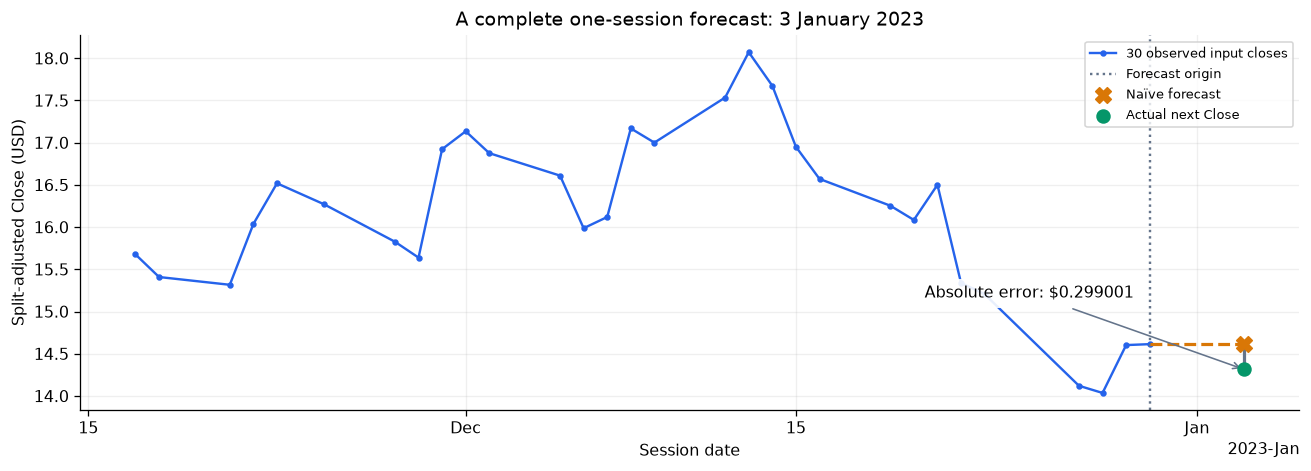

In [14]:
example_row = metadata.loc[first_validation_i]
input_sequence = close.loc[example_row.window_start:example_row.origin_date]
sequence_table = pd.DataFrame({
    "session_date": input_sequence.index,
    "input_step": np.arange(1, lookback + 1),
    "source_close_usd": input_sequence.to_numpy(),
    "dataset_close_usd": dataset.X[first_validation_i, :, 0],
    "role": ["historical input"] * (lookback - 1) + ["forecast origin: latest observed Close"],
})
display(sequence_table.style.format({"source_close_usd": "{:.6f}", "dataset_close_usd": "{:.6f}"}))
example = validation.iloc[0]
display(pd.Series({
    "window_start": example_row.window_start.date(),
    "forecast_origin": example.origin_date.date(), "target_date": example.target_date.date(),
    "latest_observed_close_usd": input_sequence.iloc[-1],
    "naive_prediction_usd": example.prediction_usd, "actual_next_close_usd": example.actual_usd,
    "signed_error_prediction_minus_actual_usd": example.error_usd,
    "absolute_error_usd": example.absolute_error_usd,
}, name="First validation forecast").to_frame())

fig, ax = plt.subplots(figsize=(11.5, 4.2))
ax.plot(input_sequence.index, input_sequence, color=BLUE, marker="o", markersize=3, label="30 observed input closes")
ax.axvline(example.origin_date, color="#64748b", linestyle=":", label="Forecast origin")
ax.plot([example.origin_date, example.target_date], [example.prediction_usd, example.prediction_usd],
        color=ORANGE, linestyle="--", linewidth=2)
ax.scatter([example.target_date], [example.prediction_usd], color=ORANGE, marker="X", s=95, zorder=4, label="Naïve forecast")
ax.scatter([example.target_date], [example.actual_usd], color=GREEN, marker="o", s=65, zorder=4, label="Actual next Close")
ax.vlines(example.target_date, example.actual_usd, example.prediction_usd, color="#64748b", linewidth=2)
ax.annotate(f"Absolute error: ${example.absolute_error_usd:.6f}",
            (example.target_date, example.actual_usd), xytext=(-200, 45),
            textcoords="offset points", bbox={"facecolor": "white", "edgecolor": "none", "alpha": .9},
            arrowprops={"arrowstyle": "->", "color": "#64748b"})
ax.set(title="A complete one-session forecast: 3 January 2023", xlabel="Session date", ylabel="Split-adjusted Close (USD)")
ax.legend(loc="upper right", fontsize=8)
dated_axis(ax)
fig.tight_layout()
show_figure(fig)


In [15]:
display(Markdown(
    f"**Walkthrough.** At the origin, the latest Close is **{example.prediction_usd:.6f} USD**. "
    f"Persistence forecasts that same price for {example.target_date.date()}. "
    f"The later observed Close is **{example.actual_usd:.6f} USD**, giving "
    f"$\\hat y-y={example.prediction_usd:.6f}-{example.actual_usd:.6f}" 
    f"={example.error_usd:+.6f}$ USD. The positive sign means an overprediction; "
    f"its absolute size is **{example.absolute_error_usd:.6f} USD**. "
    "The actual outcome scores the forecast; it does not enter that forecast's input window."
))


**Walkthrough.** At the origin, the latest Close is **14.614000 USD**. Persistence forecasts that same price for 2023-01-03. The later observed Close is **14.315000 USD**, giving $\hat y-y=14.614000-14.315000=+0.299001$ USD. The positive sign means an overprediction; its absolute size is **0.299001 USD**. The actual outcome scores the forecast; it does not enter that forecast's input window.

## 10. Forecast evaluation metrics

For aligned actual prices $y_i$ and forecasts $\hat y_i$, define the signed error as $e_i=\hat y_i-y_i$. We report:

\[
\mathrm{MAE}=\frac{1}{n}\sum_{i=1}^{n}|e_i|,\qquad
\mathrm{RMSE}=\sqrt{\frac{1}{n}\sum_{i=1}^{n}e_i^2}.
\]

MAE is the average absolute miss. RMSE squares each miss before averaging, placing more weight on large errors, then takes the square root to return to **USD**. Squared errors themselves have units of USD². Neither metric preserves direction; mean signed error describes direction separately. For the same finite errors, RMSE is at least as large as MAE.

### Small calculation checked against the actual evaluation function

For actual prices `[10, 12, 14]` and predictions `[11, 10, 17]`, errors are `[1, -2, 3]`. Thus MAE is $(1+2+3)/3=2$ USD and RMSE is $\sqrt{(1+4+9)/3}\approx2.160247$ USD. This is a mathematical demonstration; all research scores use `error_metrics()`.


In [16]:
metric_actual = np.array([10., 12., 14.])
metric_predicted = np.array([11., 10., 17.])
metric_error = metric_predicted - metric_actual
display(pd.DataFrame({"actual_usd": metric_actual, "prediction_usd": metric_predicted,
                      "signed_error_usd": metric_error, "absolute_error_usd": abs(metric_error),
                      "squared_error_usd2": metric_error ** 2}))
hand_metrics = error_metrics(metric_actual, metric_predicted)
assert hand_metrics["mae_usd"] == 2.
np.testing.assert_allclose(hand_metrics["rmse_usd"], np.sqrt(14 / 3), rtol=0, atol=1e-12)
display(pd.Series(hand_metrics, name="Production metric function").to_frame())


,actual_usd,prediction_usd,signed_error_usd,absolute_error_usd,squared_error_usd2
0,10.0,11.0,1.0,1.0,1.0
1,12.0,10.0,-2.0,2.0,4.0
2,14.0,17.0,3.0,3.0,9.0


,Production metric function
n,3.000000
mae_usd,2.000000
rmse_usd,2.160247


### Full validation benchmark and evidence checks

The evaluation uses **every eligible validation target**, without selecting favourable days. Predictions and actuals occupy the same rows in the same date order. No inverse transformation is needed because the baseline operates directly in split-adjusted USD; any model using a scaled output must reconstruct USD predictions before this comparison.


In [17]:
validation_metrics = error_metrics(validation.actual_usd, validation.prediction_usd)
recorded_metrics = recorded_summary["validation_metrics"]
assert validation_metrics["n"] == recorded_metrics["n"]
for metric in ["mae_usd", "rmse_usd"]:
    np.testing.assert_allclose(validation_metrics[metric], recorded_metrics[metric], rtol=0, atol=1e-12)
assert validation_metrics["rmse_usd"] >= validation_metrics["mae_usd"]

recorded_predictions = pd.DataFrame(json.loads((evidence_dir / "validation_predictions.json").read_text()))
for column in ["window_start", "origin_date", "target_date"]:
    recorded_predictions[column] = pd.to_datetime(recorded_predictions[column])
    np.testing.assert_array_equal(validation[column].to_numpy(), recorded_predictions[column].to_numpy())
    recorded_predictions[column] = recorded_predictions[column].astype(validation[column].dtype)
pd.testing.assert_frame_equal(validation[["window_start", "origin_date", "target_date", "split"]],
                              recorded_predictions[["window_start", "origin_date", "target_date", "split"]])
np.testing.assert_allclose(validation.prediction_usd, recorded_predictions.prediction, rtol=0, atol=1e-9)
np.testing.assert_allclose(validation.actual_usd, recorded_predictions.actual_close, rtol=0, atol=1e-9)
display(pd.DataFrame([validation_metrics, recorded_metrics], index=["Reconstructed", "Recorded reference"]))
print("All 502 target dates and forecasts match; full-precision MAE and RMSE are reproduced.")


,n,mae_usd,rmse_usd
Reconstructed,502,1.689494,2.589324
Recorded reference,502,1.689494,2.589324


All 502 target dates and forecasts match; full-precision MAE and RMSE are reproduced.


The benchmark is approximately **1.689494 USD MAE** and **2.589324 USD RMSE**. RMSE's larger value reflects unequal error magnitudes; it is not evidence of a data defect. Dollar errors must be interpreted alongside price and movement scales, particularly across different years. Lower price-forecasting error would not by itself demonstrate profitable trading after costs, execution constraints and risk.

## 11. Forecast error analysis

### Price paths: useful context, insufficient evidence of skill

A persistence curve follows actual price levels closely because it uses the preceding observed close. The full validation path shows the changing level, while a **predefined first-thirty-target zoom** exposes the one-session lag. Both panels use genuine rolling forecasts; a line between points is only a visual aid, not an additional forecast horizon.


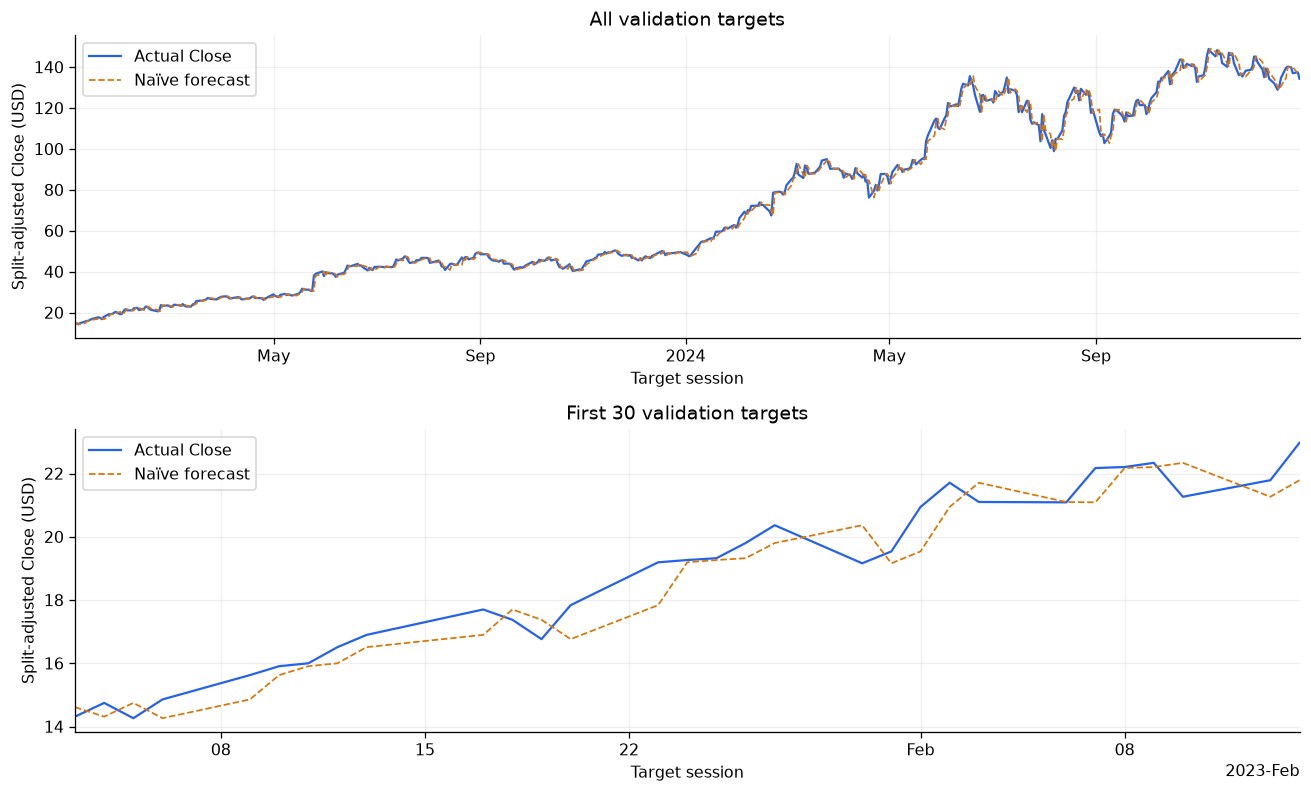

In [18]:
fig, axes = plt.subplots(2, 1, figsize=(11.5, 7))
for ax, frame, title in [(axes[0], validation, "All validation targets"),
                         (axes[1], validation.head(30), "First 30 validation targets")]:
    ax.plot(frame.target_date, frame.actual_usd, color=BLUE, linewidth=1.4, label="Actual Close")
    ax.plot(frame.target_date, frame.prediction_usd, color=ORANGE, linewidth=1.1, linestyle="--", label="Naïve forecast")
    ax.set(title=title, xlabel="Target session", ylabel="Split-adjusted Close (USD)")
    ax.legend(loc="upper left")
    dated_axis(ax)
    ax.set_xlim(frame.target_date.min(), frame.target_date.max())
fig.tight_layout()
show_figure(fig)


### Signed errors, extreme observations and dollar changes

For persistence, the error has an exact relationship to the realised dollar move:

\[
e_{t+1}=\hat C_{t+1}-C_{t+1}=C_t-C_{t+1}=-\Delta C_{t+1}.
\]

Consequently, large absolute persistence errors are **exactly** large absolute one-session dollar changes. This is an algebraic property, not evidence of a causal relationship discovered by correlation. Negative errors correspond to price rises; positive errors correspond to price falls.

The time plot reveals when misses are large; the histogram describes their distribution without assuming normality. The largest-error table helps identify observations that strongly influence RMSE. Unusual moves are retained unless separate data-quality evidence establishes an error. We do not attribute them to news events without evidence.


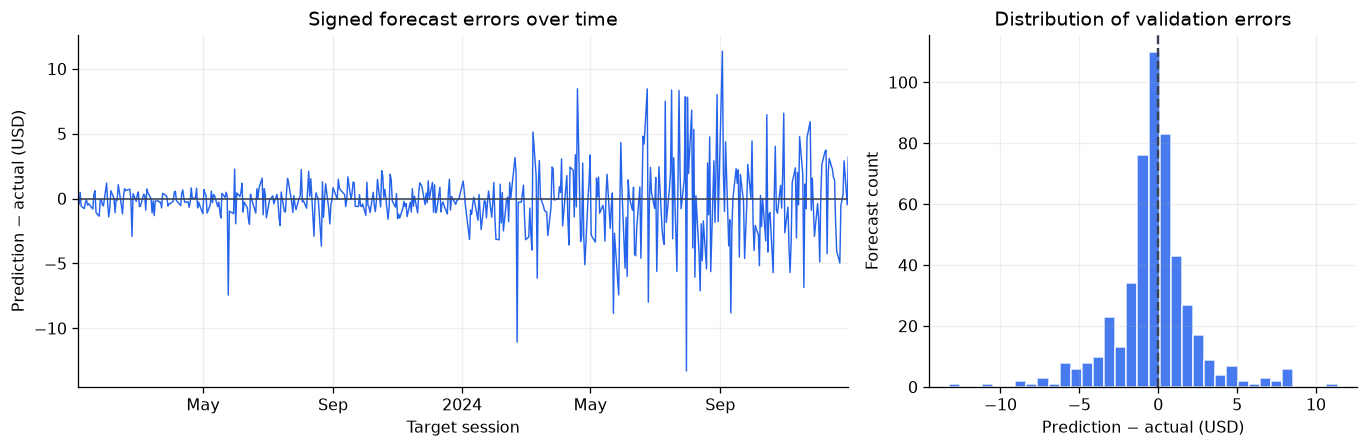

,origin_date,target_date,prediction_usd,actual_usd,error_usd,absolute_error_usd,squared_error_usd2,share_of_total_squared_error_pct
395,2024-07-30 00:00:00,2024-07-31 00:00:00,103.730003,117.019997,-13.289993,13.289993,176.623922,5.247749
418,2024-08-30 00:00:00,2024-09-03 00:00:00,119.370003,108.000000,11.370003,11.370003,129.276962,3.841003
285,2024-02-21 00:00:00,2024-02-22 00:00:00,67.472000,78.538002,-11.066002,11.066002,122.456398,3.638355
349,2024-05-22 00:00:00,2024-05-23 00:00:00,94.949997,103.799004,-8.849007,8.849007,78.304919,2.326551
424,2024-09-10 00:00:00,2024-09-11 00:00:00,108.099998,116.910004,-8.810005,8.810005,77.616191,2.306088


,Validation error diagnostics
mean_signed_error_usd,-0.238398
median_absolute_error_usd,1.013994
maximum_absolute_error_usd,13.289993
sample_error_skewness,-0.067843
top_five_share_of_squared_error_pct,17.359746


In [19]:
validation["observed_change_usd"] = close.diff().reindex(validation.target_date).to_numpy()
np.testing.assert_allclose(validation.error_usd, -validation.observed_change_usd, rtol=0, atol=1e-12)
fig, axes = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [1.8, 1]})
axes[0].plot(validation.target_date, validation.error_usd, color=BLUE, linewidth=.9)
axes[0].axhline(0, color="#374151", linewidth=1)
axes[0].set(title="Signed forecast errors over time", xlabel="Target session", ylabel="Prediction − actual (USD)")
dated_axis(axes[0])
axes[0].set_xlim(validation.target_date.min(), validation.target_date.max())
axes[1].hist(validation.error_usd, bins=35, color=BLUE, edgecolor="white", alpha=.85)
axes[1].axvline(0, color="#374151", linestyle="--")
axes[1].set(title="Distribution of validation errors", xlabel="Prediction − actual (USD)", ylabel="Forecast count")
fig.tight_layout()
show_figure(fig)

largest_errors = validation.loc[validation.absolute_error_usd.nlargest(5).index,
    ["origin_date", "target_date", "prediction_usd", "actual_usd", "error_usd", "absolute_error_usd", "squared_error_usd2"]].copy()
largest_errors["share_of_total_squared_error_pct"] = (
    100 * largest_errors.squared_error_usd2 / validation.squared_error_usd2.sum()
)
display(largest_errors.style.format({column: "{:.6f}" for column in largest_errors.select_dtypes("number").columns}))
error_summary = pd.Series({
    "mean_signed_error_usd": validation.error_usd.mean(),
    "median_absolute_error_usd": validation.absolute_error_usd.median(),
    "maximum_absolute_error_usd": validation.absolute_error_usd.max(),
    "sample_error_skewness": validation.error_usd.skew(),
    "top_five_share_of_squared_error_pct": largest_errors.share_of_total_squared_error_pct.sum(),
})
display(error_summary.to_frame("Validation error diagnostics"))


In [20]:
worst = validation.loc[validation.absolute_error_usd.idxmax()]
display(Markdown(
    f"**Interpretation.** The largest absolute miss is **{worst.absolute_error_usd:.6f} USD** "
    f"on **{worst.target_date.date()}**, a {('price rise' if worst.error_usd < 0 else 'price fall')} "
    "relative to the origin close. The five largest misses account for "
    f"**{error_summary['top_five_share_of_squared_error_pct']:.2f}%** of total squared error, "
    f"illustrating RMSE's sensitivity to large moves. Mean signed error is "
    f"**{error_summary['mean_signed_error_usd']:+.6f} USD**, indicating average underprediction "
    "over this interval, not a guarantee of directional bias in another period. "
    f"Sample skewness is **{error_summary['sample_error_skewness']:.3f}**; this single summary "
    "does not establish a distributional model or statistical significance."
))


**Interpretation.** The largest absolute miss is **13.289993 USD** on **2024-07-31**, a price rise relative to the origin close. The five largest misses account for **17.36%** of total squared error, illustrating RMSE's sensitivity to large moves. Mean signed error is **-0.238398 USD**, indicating average underprediction over this interval, not a guarantee of directional bias in another period. Sample skewness is **-0.068**; this single summary does not establish a distributional model or statistical significance.

### Comparing 2023 and 2024 without confusing dollar and relative scale

We use the same metric function for each year. Mean origin Close provides a price-scale reference. As a descriptive scale check, we also report the mean absolute one-session percentage move, $100\,|C_{t+1}-C_t|/C_t$. Its denominator is the **origin price**, so it is not conventional MAPE. It is not a replacement model-selection metric.

The boxplots show each year's median, quartiles and spread of absolute errors. Points beyond the conventional 1.5-IQR whiskers are displayed, not removed. Higher dollar error in a higher-priced year can reflect larger dollar movements; the comparison cannot isolate a causal effect of price level or market conditions.


,n,mae_usd,rmse_usd,mean_origin_close_usd,mean_absolute_move_pct_of_origin
year,,,,,
2023,250,0.730728,1.022887,36.429628,2.138067
2024,252,2.640651,3.509699,107.489079,2.490152


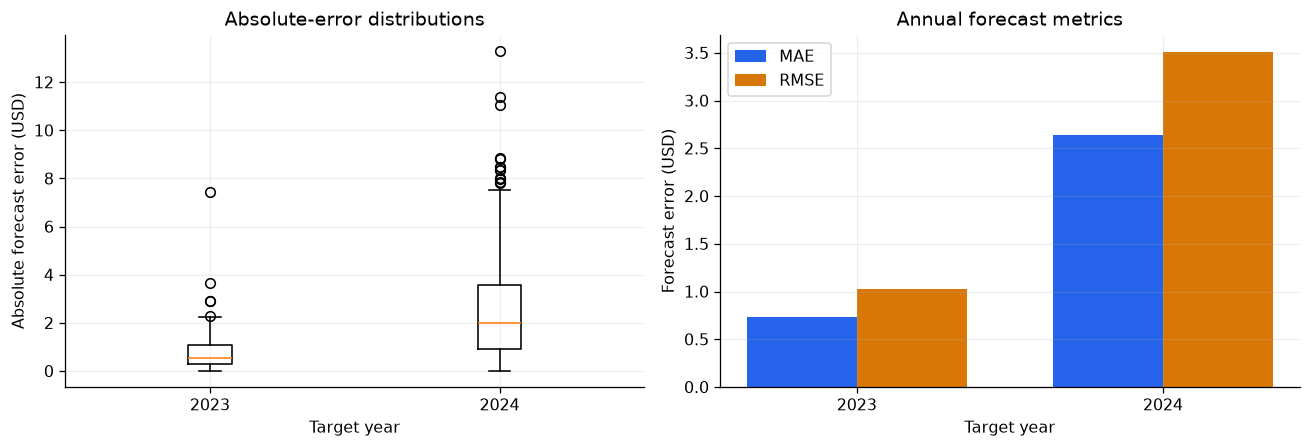

In [21]:
annual_rows = []
for year, group in validation.groupby("year"):
    annual_rows.append({"year": int(year), **error_metrics(group.actual_usd, group.prediction_usd),
                       "mean_origin_close_usd": group.prediction_usd.mean(),
                       "mean_absolute_move_pct_of_origin": (100 * group.observed_change_usd.abs() / group.prediction_usd).mean()})
annual_metrics = pd.DataFrame(annual_rows).set_index("year")
display(annual_metrics.round(6))

# Aggregate MAE is count-weighted; aggregate RMSE weights squared RMSE before its root.
np.testing.assert_allclose(np.average(annual_metrics.mae_usd, weights=annual_metrics.n), validation_metrics["mae_usd"])
np.testing.assert_allclose(np.sqrt(np.average(annual_metrics.rmse_usd ** 2, weights=annual_metrics.n)), validation_metrics["rmse_usd"])
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4))
years = annual_metrics.index.tolist()
axes[0].boxplot([validation.loc[validation.year.eq(year), "absolute_error_usd"] for year in years],
                tick_labels=[str(year) for year in years], showfliers=True)
axes[0].set(title="Absolute-error distributions", xlabel="Target year", ylabel="Absolute forecast error (USD)")
positions = np.arange(len(years))
axes[1].bar(positions - .18, annual_metrics.mae_usd, .36, color=BLUE, label="MAE")
axes[1].bar(positions + .18, annual_metrics.rmse_usd, .36, color=ORANGE, label="RMSE")
axes[1].set_xticks(positions, [str(year) for year in years])
axes[1].set(title="Annual forecast metrics", xlabel="Target year", ylabel="Forecast error (USD)")
axes[1].legend()
fig.tight_layout()
show_figure(fig)


In [22]:
a23, a24 = annual_metrics.loc[2023], annual_metrics.loc[2024]
display(Markdown(
    f"**Year comparison.** MAE rises from **{a23.mae_usd:.6f} USD** in 2023 "
    f"({int(a23.n)} targets) to **{a24.mae_usd:.6f} USD** in 2024 ({int(a24.n)} targets), "
    f"a **{a24.mae_usd / a23.mae_usd:.2f}×** increase. RMSE is "
    f"**{a23.rmse_usd:.6f} USD** and **{a24.rmse_usd:.6f} USD**, respectively. "
    f"Mean origin Close increases from **{a23.mean_origin_close_usd:.2f} USD** to "
    f"**{a24.mean_origin_close_usd:.2f} USD**; mean absolute percentage movement changes from "
    f"**{a23.mean_absolute_move_pct_of_origin:.3f}%** to **{a24.mean_absolute_move_pct_of_origin:.3f}%**. "
    "Both dollar and percentage movement summaries change, but their relative increases differ. "
    "This extends the distinction between price level, dollar variability and relative variability "
    "established in Notebook 01. It does not establish that the forecasting rule itself deteriorated "
    "for a particular causal reason."
))


**Year comparison.** MAE rises from **0.730728 USD** in 2023 (250 targets) to **2.640651 USD** in 2024 (252 targets), a **3.61×** increase. RMSE is **1.022887 USD** and **3.509699 USD**, respectively. Mean origin Close increases from **36.43 USD** to **107.49 USD**; mean absolute percentage movement changes from **2.138%** to **2.490%**. Both dollar and percentage movement summaries change, but their relative increases differ. This extends the distinction between price level, dollar variability and relative variability established in Notebook 01. It does not establish that the forecasting rule itself deteriorated for a particular causal reason.

## 12. Research findings and methodological implications

The combined evidence supports the production window arithmetic, target-date partitions, persistence forecast and metric formulas. **The same examples, targets and scores are preserved**, with explicit input-contract and precondition checks:

- The builder accepts a one-dimensional Close `Series`; a DataFrame is rejected because it would introduce an unintended extra array dimension.
- The baseline script checks snapshot identity, loads only the development interval and enforces the independent calendar audit before constructing windows or writing evidence.
- The notebook executes those reusable loading, audit, dataset, forecasting and evaluation functions. It verifies intermediate values and compares the result with the preserved artifact evidence.

These checks support the implementation for the permitted data and tested contracts; they are not a proof against every possible data or software fault.


In [23]:
verification = pd.Series({
    "permitted source values only": close.index.max() <= VALIDATION_END,
    "calendar coverage complete": not calendar_audit["missing"] and not calendar_audit["unexpected"],
    "input tensor has samples × 30 × 1 shape": dataset.X.shape == (len(metadata), lookback, 1),
    "every origin precedes its target": bool((metadata.origin_date < metadata.target_date).all()),
    "target dates are unique and chronological": bool(metadata.target_date.is_unique and metadata.target_date.is_monotonic_increasing),
    "training targets respect training boundary": bool((metadata.loc[train_mask, "target_date"] <= TRAIN_END).all()),
    "no reserved target is constructed": metadata.target_date.max() <= VALIDATION_END,
    "persistence equals latest observed Close": bool(np.array_equal(predictions, dataset.X[:, -1, 0])),
    "recorded MAE reproduced": bool(np.isclose(validation_metrics["mae_usd"], recorded_metrics["mae_usd"], rtol=0, atol=1e-12)),
    "recorded RMSE reproduced": bool(np.isclose(validation_metrics["rmse_usd"], recorded_metrics["rmse_usd"], rtol=0, atol=1e-12)),
}, name="Passed")
assert verification.all()
display(verification.to_frame())
display(Markdown(
    f"**Established result:** {len(metadata):,} correctly aligned development examples, "
    f"including {train_mask.sum():,} training and {validation_mask.sum():,} validation targets. "
    f"The naïve benchmark achieves **MAE {validation_metrics['mae_usd']:.9f} USD** and "
    f"**RMSE {validation_metrics['rmse_usd']:.9f} USD** over the shared validation dates. "
    "Exact array/metadata agreement and the recorded forecast comparison establish reproducibility "
    "without overwriting any original experiment."
))


,Passed
permitted source values only,True
calendar coverage complete,True
input tensor has samples × 30 × 1 shape,True
every origin precedes its target,True
target dates are unique and chronological,True
training targets respect training boundary,True
no reserved target is constructed,True
persistence equals latest observed Close,True
recorded MAE reproduced,True
recorded RMSE reproduced,True


**Established result:** 2,486 correctly aligned development examples, including 1,984 training and 502 validation targets. The naïve benchmark achieves **MAE 1.689494114 USD** and **RMSE 2.589323812 USD** over the shared validation dates. Exact array/metadata agreement and the recorded forecast comparison establish reproducibility without overwriting any original experiment.

### Requirements for subsequent models

1. **Preserve forecast availability and alignment.** Use only information available at each origin and compare predictions on the same eligible target dates. Separate any shorter-history training eligibility from external evaluation alignment.
2. **Fit transformations only on fitting observations.** Chronological internal validation requires its own permitted fitting subset. Avoid random window splits, future-derived scaling and backfilling.
3. **Evaluate the economic target in USD.** For residual forecasting, $\hat C_{t+1}=C_t+\widehat{\Delta C}_{t+1}$. A zero-dollar correction reproduces persistence. A correction must be inverse-transformed before reconstruction; zero in a standardised scale need not mean zero dollars.
4. **Keep feature comparisons controlled.** Indicators and market-context features must be causal, aligned and subject to explicit warm-up rules. Compare variants on common eligible examples so feature effects are not confused with changes in available history.
5. **Report more than a price chart.** Retain full-period and annual metrics, error distributions and limitations. Changing dollar scales can challenge a model even when input order is correct. A lower validation error does not establish trading profitability or superiority in an unseen period.
6. **Keep final-test information reserved.** Development-period results cannot establish 2025 generalisation. Freeze the final methodology before any access to its targets or performance.

**Limitations.** These are retrospective vendor-adjusted prices, not a point-in-time trading simulation. Calendar checks use a library, not exchange certification. Overlapping inputs and sequential errors limit independence assumptions; no confidence interval or significance claim is made here. Thirty sessions is a controlled setting, not an optimality result. Persistence is a transparent benchmark, and a more sophisticated model may fail to improve on it.

**Supporting methodology:** [Data conventions](../docs/DATA_CONVENTIONS.md), [dataset construction](../docs/MILESTONE_3.md), [benchmark protocol and results](../docs/MILESTONE_4.md). The authoritative implementation is in [dataset.py](../src/market_forecasting/dataset.py); automated alignment and safeguard checks are in [test_milestone2.py](../tests/test_milestone2.py).
